# 11 — CNNs: deep learning on the person crops

**Part B — Vision with deep learning.** In part A we chose the descriptor by hand (HOG, LBP…). A **CNN** (convolutional neural network) **learns its own descriptor** from the images.

Same task as part A: **one crop → one posture** (*not lying, falling, lying*). We compare 4 networks:
- a **small CNN from scratch** (our reference);
- **MobileNetV2, ResNet18, ResNet50**, already trained on ImageNet (1.2 million photos) and then retrained on our crops: this is **transfer learning**.

**Rules decided in notebook 08:** predict postures (not fall / no fall directly), use the **strict groups** as the main test, choose settings on **validation** videos only, and look at ADL and fall videos **separately**.

In [1]:
from pathlib import Path
import re, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path("..") / "data" / "raw" / "urfd"
PROC = Path("..") / "data" / "processed"
CNN = PROC / "cnn"; CNN.mkdir(exist_ok=True)
NAMES = ["not lying", "falling", "lying"]           # class 0, 1, 2 for the networks (label -1, 0, 1 in the dataset)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

torch 2.5.1+cu121 | NVIDIA GeForce RTX 4050 Laptop GPU


💡 **Interpretation:** the networks run on the laptop GPU (RTX 4050) with PyTorch 2.5.1.

## Step 1 — Bigger crops and the two kinds of groups

CNNs need more detail than HOG, so we cut the same person boxes at **128 × 128** (notebooks 04-07 used 64 × 64). They are made once and saved.
- **Strict groups** (`video_groups.csv`, notebook 08): main test, with new recording sessions and new clothes.
- **Random groups** (notebooks 02 and 04-07): only to compare with part A.

In [2]:
CROPS = PROC / "crops128.npz"

def frames_of(video):
    return {int(re.search(r"-(\d+)\.png$", p.name).group(1)): p for p in (ROOT / "rgb" / video).rglob("*.png")}

def crop_person(image, box, size=128):   # same function as notebooks 03 and 04
    x, y, w, h = box
    side = int(max(w, h) * 1.1)
    cx, cy = x + w // 2, y + h // 2
    padded = cv2.copyMakeBorder(image, side, side, side, side, cv2.BORDER_CONSTANT, value=0)
    x0, y0 = cx - side // 2 + side, cy - side // 2 + side
    return cv2.resize(padded[y0:y0 + side, x0:x0 + side], (size, size))

boxes = pd.read_csv(PROC / "person_boxes.csv").dropna().astype({"x": int, "y": int, "w": int, "h": int})
if not CROPS.exists():
    out = []
    for video, d in boxes.groupby("video", sort=False):
        files = frames_of(video)
        out += [crop_person(cv2.cvtColor(cv2.imread(str(files[r.frame])), cv2.COLOR_BGR2RGB), (r.x, r.y, r.w, r.h)) for r in d.itertuples()]
    np.savez(CROPS, crops=np.stack(out), video=np.array(boxes.video.tolist(), dtype="U8"), frame=boxes.frame.to_numpy())

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2]) for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]
z = np.load(CROPS)
frames = pd.DataFrame({"video": z["video"], "frame": z["frame"]}).merge(labels, on=["video", "frame"], how="left")
keep = frames.frame_label.notna().to_numpy()
crops, frames = z["crops"][keep], frames[keep].reset_index(drop=True)
y = frames.frame_label.astype(int).to_numpy() + 1      # 0 = not lying, 1 = falling, 2 = lying

from sklearn.model_selection import StratifiedKFold
videos = np.array(sorted(frames.video.unique()))
random_of = {}
for k, (_, test) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(videos, np.char.startswith(videos.astype(str), "fall").astype(int))):
    random_of.update({v: k + 1 for v in videos[test]})
strict_of = pd.read_csv(Path("..") / "video_groups.csv").set_index("video").group.to_dict()
GROUPS = {"strict": frames.video.map(strict_of).to_numpy(), "random": frames.video.map(random_of).to_numpy()}
print(crops.shape)
pd.DataFrame({name: pd.Series(g).value_counts().sort_index() for name, g in GROUPS.items()}).rename_axis("group")

(11027, 128, 128, 3)


,strict,random
group,,
1,2953,2175
2,2803,2321
3,1007,2227
4,2341,2044
5,1923,2260


💡 **Interpretation:** same 11,027 labelled crops as part A, now 128 × 128. The random groups have similar sizes (2,044 to 2,321), the strict ones do not (1,007 to 2,953),
so the strict training sets are not all the same size.

## Step 2 — Data augmentation

To learn the posture and not the exact picture, each training crop is changed a little every time it is seen:
- **horizontal flip** (a fall to the left or to the right is the same);
- **brightness** × 0.7 to 1.3 (rooms are lit differently).

**No big rotation:** turning a standing person by 90° would make them look lying, with the wrong label.

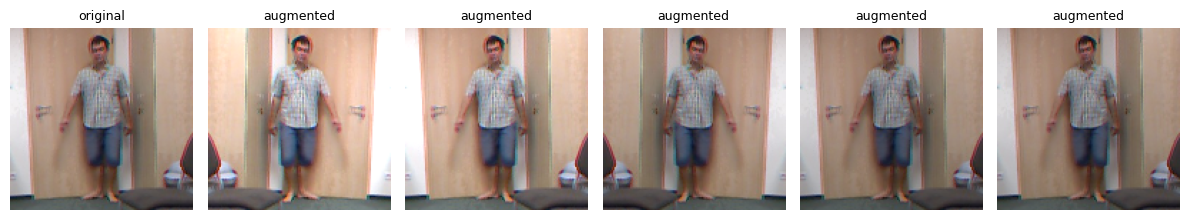

In [3]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)    # the normalisation ImageNet networks expect
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def augment(x):                                  # x: batch of uint8 images on the GPU
    x = x.float() / 255
    flip = torch.rand(len(x), 1, 1, 1, device=x.device) < 0.5
    x = torch.where(flip, x.flip(3), x)
    return (x * (0.7 + 0.6 * torch.rand(len(x), 1, 1, 1, device=x.device))).clamp(0, 1)

X = torch.from_numpy(crops).permute(0, 3, 1, 2).to(device)
torch.manual_seed(0)
i = int(np.flatnonzero((frames.video == "fall-01").to_numpy() & (y == 0))[20])
shown = augment(X[i:i + 1].repeat(5, 1, 1, 1)).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(crops[i]); axes[0].set_title("original", fontsize=9)
for ax, s in zip(axes[1:], shown):
    ax.imshow(s); ax.set_title("augmented", fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

💡 **Interpretation:** the same crop appears flipped, brighter or darker, and the posture stays the same, so the label is still true.
The room is still fully visible: these changes do **not** hide the background.

## Step 3 — The four networks

- **Small CNN:** 4 blocks (*convolution → normalisation → ReLU → pooling*), then one layer that gives the 3 postures.
- **Pretrained networks:** we keep all their layers and replace only the **last layer** (1,000 ImageNet classes → our 3 postures). Then **all** layers are trained slowly (*fine-tuning*).

In [4]:
def small_cnn():
    layers, channels = [], 3
    for out in [16, 32, 64, 128]:
        layers += [nn.Conv2d(channels, out, 3, padding=1), nn.BatchNorm2d(out), nn.ReLU(), nn.MaxPool2d(2)]
        channels = out
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 3))

def make(name):
    if name == "small CNN":
        return small_cnn()
    if name == "MobileNetV2":
        net = models.mobilenet_v2(weights="IMAGENET1K_V1")
        net.classifier[1] = nn.Linear(net.last_channel, 3)
        return net
    net = {"ResNet18": models.resnet18, "ResNet50": models.resnet50}[name](weights="IMAGENET1K_V1")
    net.fc = nn.Linear(net.fc.in_features, 3)
    return net

MODELS = {"small CNN": 1e-3, "MobileNetV2": 1e-4, "ResNet18": 1e-4, "ResNet50": 1e-4}    # learning rate of each network
rows = []
with torch.no_grad():
    for name in MODELS:
        net = make(name).to(device).eval()
        net(X[:64].float() / 255)
        torch.cuda.synchronize(); t = time.time()
        for _ in range(20):
            net(X[:64].float() / 255)
        torch.cuda.synchronize()
        rows.append({"network": name, "parameters (millions)": sum(p.numel() for p in net.parameters()) / 1e6,
                     "ms per image (GPU, batch of 64)": (time.time() - t) / 20 / 64 * 1000})
sizes = pd.DataFrame(rows).round(2)
sizes

,network,parameters (millions),"ms per image (GPU, batch of 64)"
0,small CNN,0.10,0.11
1,MobileNetV2,2.23,0.23
2,ResNet18,11.18,0.21
3,ResNet50,23.51,0.71


💡 **Interpretation:** ResNet50 is the biggest (23.5 million parameters) and the slowest (0.71 ms per image), about 10 times the size of MobileNetV2.
All of them are far faster than the 30 images per second of a camera; finding the person (notebook 03) is not counted here.

## Step 4 — How we train (the same for all networks)

For each test group, the **next group is the validation group** and the 3 others are for training:
1. train for **8 epochs** (8 passes over the training crops; 1 frame out of 2, because neighbouring frames are almost identical);
2. after each epoch, measure the macro F1 on the **validation** group and keep the **best epoch**;
3. only then predict the **test** group. The test videos never influence any choice.

*Class weights* make the rare postures count as much as the frequent one. Each network is trained with **3 random starts** (seeds), because deep learning results change from run to run. All the predictions are saved, so this cell takes long only the first time.

In [5]:
Y = torch.from_numpy(y).to(device)

def predict(net, index, images=None):
    images = X if images is None else images
    net.eval(); out = []
    with torch.no_grad(), torch.autocast(device):
        for b in torch.split(index, 256):
            out.append(net((images[b].float() / 255 - MEAN) / STD).argmax(1))
    return torch.cat(out).cpu().numpy()

def train_one(name, groups, test, seed, epochs=8):
    g, val = GROUPS[groups], test % 5 + 1
    train = np.flatnonzero((g != test) & (g != val))
    train = torch.from_numpy(train[::2]).to(device)
    val_index, test_index = (torch.from_numpy(np.flatnonzero(g == k)).to(device) for k in (val, test))
    torch.manual_seed(seed)
    net = make(name).to(device)
    weight = 1 / torch.bincount(Y[train], minlength=3).float()
    opt = torch.optim.AdamW(net.parameters(), lr=MODELS[name], weight_decay=1e-2)
    scaler = torch.amp.GradScaler(device)
    best_f1, best_state, history = -1, None, []
    for epoch in range(epochs):
        net.train(); total = 0
        for b in torch.split(train[torch.randperm(len(train), device=device)], 64):
            if len(b) < 2: continue
            with torch.autocast(device):
                loss = nn.functional.cross_entropy(net((augment(X[b]) - MEAN) / STD), Y[b], weight=weight / weight.mean())
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            total += loss.item() * len(b)
        train_f1 = f1_score(y[train.cpu()], predict(net, train), average="macro")
        val_f1 = f1_score(y[val_index.cpu()], predict(net, val_index), average="macro")
        history.append({"groups": groups, "network": name, "seed": seed, "test": test, "epoch": epoch + 1,
                        "train loss": total / len(train), "train macro F1": train_f1, "val macro F1": val_f1})
        if val_f1 > best_f1:
            best_f1, best_state = val_f1, {k: v.detach().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return net, test_index.cpu().numpy(), predict(net, test_index), pd.DataFrame(history)

def run(name, groups, seed):
    pred_file, hist_file = CNN / f"{groups}_{name}_{seed}.csv".replace(" ", ""), CNN / f"{groups}_{name}_{seed}_history.csv".replace(" ", "")
    if pred_file.exists() and hist_file.exists():
        return pd.read_csv(pred_file).pred.to_numpy(), pd.read_csv(hist_file)
    pred, hist = np.zeros(len(y), int), []
    for test in range(1, 6):
        net, index, p, h = train_one(name, groups, test, seed)
        pred[index] = p; hist.append(h)
        if groups == "strict" and seed == 0:
            torch.save(net.state_dict(), CNN / f"strict_{name}_test{test}.pt".replace(" ", ""))
    hist = pd.concat(hist)
    hist.to_csv(hist_file, index=False)
    frames[["video", "frame"]].assign(pred=pred).to_csv(pred_file, index=False)
    return pred, hist

t = time.time()
results = {}
for name in MODELS:
    for seed in range(3):
        results["strict", name, seed] = run(name, "strict", seed)
    results["random", name, 0] = run(name, "random", 0)
print(f"{(time.time() - t) / 60:.0f} min (0 if loaded from the saved files)")

0 min (0 if loaded from the saved files)


💡 **Interpretation:** 16 trainings (4 networks × 4) of 5 groups each, loaded here from the saved files; their dates show about 15 minutes for one ResNet50 training.
The 12 strict ones give 60 chosen epochs, spread from 1 to 8 (12 are epoch 8): the best moment changes a lot from one split to another.

## Step 5 — Scores on the frames

For the strict groups we give the average of the 3 random starts, and the lowest-highest macro F1. The part A rows come from notebook 08.

**A fair detail:** our CNNs learn from only **3 groups** (the 4th is for validation), part A from 4. So we also train two part A methods on the **same 3 groups**.

In [6]:
from skimage.feature import hog
from sklearn.svm import SVC

rows = []
for name in MODELS:
    f1 = [f1_score(y, results["strict", name, s][0], average="macro") for s in range(3)]
    rows.append({"method": name, "accuracy (strict)": np.mean([accuracy_score(y, results["strict", name, s][0]) for s in range(3)]),
                 "macro F1 (strict)": np.mean(f1), "lowest": min(f1), "highest": max(f1),
                 "accuracy (random)": accuracy_score(y, results["random", name, 0][0]), "macro F1 (random)": f1_score(y, results["random", name, 0][0], average="macro")})

small = np.stack([cv2.resize(c, (64, 64), interpolation=cv2.INTER_AREA) for c in crops])
def hsv_grid(image):
    h = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    return np.hstack([cv2.calcHist([np.ascontiguousarray(h[a:a + 16, b:b + 16])], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).ravel() / 256
                      for a in range(0, 64, 16) for b in range(0, 64, 16)])
features = {"HOG + SVM": np.stack([hog(cv2.cvtColor(c, cv2.COLOR_RGB2GRAY), orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2)) for c in small]),
            "Colour (HSV) + SVM": np.stack([hsv_grid(c) for c in small])}
strict_a = pd.read_csv(PROC / "results_traditional_strict.csv"); random_a = pd.read_csv(PROC / "results_traditional.csv")
g, three = GROUPS["strict"], {}
for name, F in features.items():
    d, c = name.split(" + ")
    old_s, old_r = (t[(t.descriptor == d) & (t.classifier == c)].iloc[0] for t in (strict_a, random_a))
    rows.append({"method": f"{name} (part A, 4 groups)", "accuracy (strict)": old_s["frame accuracy"], "macro F1 (strict)": old_s["macro F1"],
                 "accuracy (random)": old_r["frame accuracy"], "macro F1 (random)": old_r["macro F1"]})
    p = np.zeros(len(y), int)
    for test in range(1, 6):
        train = (g != test) & (g != test % 5 + 1)
        p[g == test] = SVC(kernel="rbf").fit(F[train], y[train]).predict(F[g == test])
    three[name] = p
    rows.append({"method": f"{name} (same 3 groups)", "accuracy (strict)": accuracy_score(y, p), "macro F1 (strict)": f1_score(y, p, average="macro")})
frame_scores = pd.DataFrame(rows).round(3)
frame_scores

,method,accuracy (strict),macro F1 (strict),lowest,highest,accuracy (random),macro F1 (random)
0,small CNN,0.538,0.495,0.424,0.592,0.806,0.743
1,MobileNetV2,0.755,0.689,0.677,0.708,0.889,0.845
2,ResNet18,0.693,0.628,0.622,0.636,0.891,0.847
3,ResNet50,0.746,0.671,0.665,0.682,0.895,0.856
4,"HOG + SVM (part A, 4 groups)",0.749,0.639,NaN,NaN,0.859,0.795
5,HOG + SVM (same 3 groups),0.675,0.581,NaN,NaN,NaN,NaN
6,"Colour (HSV) + SVM (part A, 4 groups)",0.784,0.662,NaN,NaN,0.886,0.834
7,Colour (HSV) + SVM (same 3 groups),0.745,0.594,NaN,NaN,NaN,NaN


💡 **Interpretation:** on the same 3 groups, the pretrained CNNs beat HOG and colour (macro F1 **0.63-0.69** vs 0.58-0.59); MobileNetV2 (0.689) and ResNet50 (0.671) pass part A's best (0.662), which had 4 groups.
No CNN beats colour's accuracy (**0.784**), the small CNN is below everything (and unstable, 0.42-0.59), and random groups are again too optimistic (about 0.85).

## Step 6 — Learning curves: do the networks overfit?

Average over the 5 test groups and the 3 random starts (strict groups). A network **overfits** when the training score goes up but the validation score does not follow: it remembers the training images.

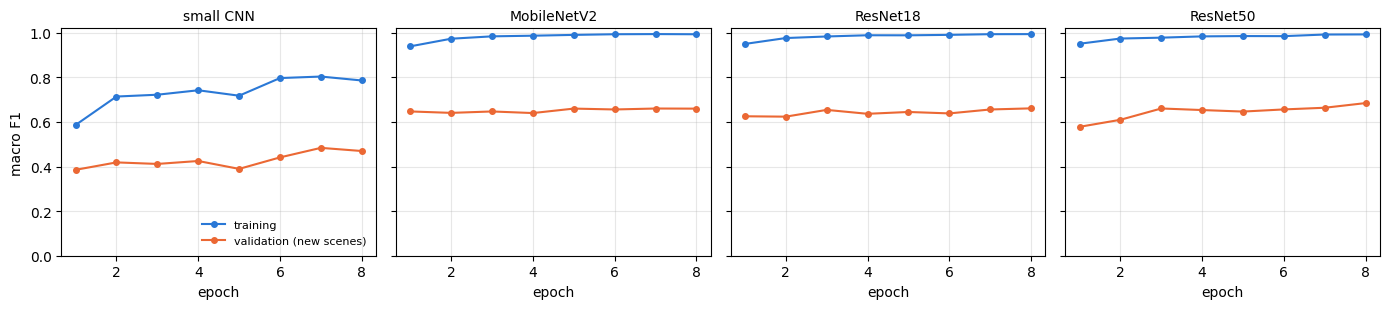

             train macro F1  val macro F1
network                                  
small CNN              0.79          0.47
MobileNetV2            0.99          0.66
ResNet18               0.99          0.66
ResNet50               0.99          0.68

mean of the best validation macro F1: {'small CNN': 0.583, 'MobileNetV2': 0.704, 'ResNet18': 0.695, 'ResNet50': 0.725}
network chosen on the VALIDATION groups: ResNet50


In [7]:
history = pd.concat([results["strict", n, s][1] for n in MODELS for s in range(3)])
curves = history.groupby(["network", "epoch"])[["train macro F1", "val macro F1"]].mean()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, name in zip(axes, MODELS):
    c = curves.loc[name]
    ax.plot(c.index, c["train macro F1"], color="#2a78d6", marker="o", markersize=4, label="training")
    ax.plot(c.index, c["val macro F1"], color="#eb6834", marker="o", markersize=4, label="validation (new scenes)")
    ax.set_title(name, fontsize=10); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("macro F1"); axes[0].legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
print(curves.groupby("network").last().round(2).loc[list(MODELS)])
best_val = history.groupby(["network", "seed", "test"])["val macro F1"].max().groupby("network").mean().round(3)
print("\nmean of the best validation macro F1:", best_val.loc[list(MODELS)].to_dict())
best = best_val.idxmax()
print("network chosen on the VALIDATION groups:", best)

💡 **Interpretation:** the pretrained networks reach **0.99** in training but only **0.66-0.68** on new scenes: they overfit, and the validation curve is almost flat, except ResNet50 (0.58 → 0.68).
The validation groups choose **ResNet50** (0.725), a little before MobileNetV2 (0.704).

## Step 7 — ADL and fall videos separately

Notebook 08 showed why this is needed: all the falls are in one office, always seen in training, while the ADL rooms are new. We measure the share of the frames of each posture that are recognised (average of the 3 random starts).

In [8]:
fall_frame = frames.video.str.startswith("fall").to_numpy()
def recognised(p):
    return {f"{NAMES[k]} in {kind} videos": np.mean(p[mask & (y == k)] == k) for kind, mask in [("ADL", ~fall_frame), ("fall", fall_frame)] for k in (1, 2)} | {"all frames answered falling": np.mean(p == 1)}
seen = {name: pd.DataFrame([recognised(results["strict", name, s][0]) for s in range(3)]).mean() for name in MODELS}
seen.update({f"{name} (same 3 groups)": pd.Series(recognised(p)) for name, p in three.items()})
print("true share of falling:", round(float(np.mean(y == 1)), 2))
pd.DataFrame(seen).T.round(2)

true share of falling: 0.16


,falling in ADL videos,lying in ADL videos,falling in fall videos,lying in fall videos,all frames answered falling
small CNN,0.57,0.46,0.58,0.78,0.33
MobileNetV2,0.34,0.77,0.79,0.78,0.20
ResNet18,0.46,0.47,0.77,0.82,0.25
ResNet50,0.37,0.58,0.76,0.81,0.22
HOG + SVM (same 3 groups),0.22,0.28,0.75,0.68,0.22
Colour (HSV) + SVM (same 3 groups),0.00,0.10,0.66,0.75,0.08


💡 **Interpretation:** in the **new ADL rooms** the pretrained CNNs recognise more *falling* (0.34-0.46) and *lying* (0.47-0.77) than HOG and colour (at most 0.22 and 0.28), but *falling* stays far below the fall videos (0.76-0.79).
The small CNN's 0.57 is not a success: it answers *falling* for 33% of the frames (true share 16%).

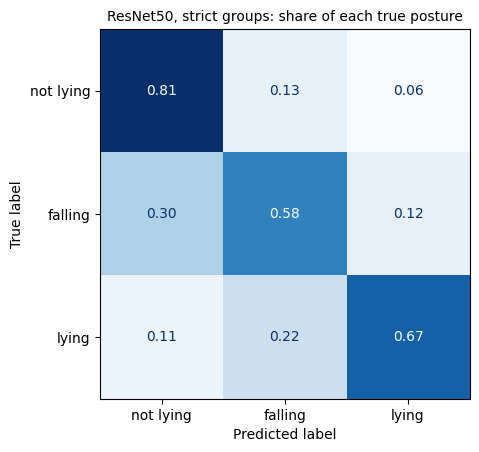

macro F1 per test group: {1: 0.75, 2: 0.53, 3: 0.65, 4: 0.61, 5: 0.73}


In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = np.mean([confusion_matrix(y, results["strict", best, s][0], normalize="true") for s in range(3)], axis=0)
ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(cmap="Blues", values_format=".2f", colorbar=False)
plt.title(f"{best}, strict groups: share of each true posture", fontsize=10); plt.show()
each = {g_: round(float(np.mean([f1_score(y[g == g_], results['strict', best, s][0][g == g_], average='macro') for s in range(3)])), 2) for g_ in range(1, 6)}
print("macro F1 per test group:", each)

💡 **Interpretation:** ResNet50 recognises 81% of *not lying*, 67% of *lying* and 58% of *falling*; it confuses 22% of *lying* with *falling*, and 30% of *falling* with *not lying*.
The score changes a lot with the test group: from **0.53** (group 2) to **0.75** (group 1).

## Step 8 — From frames to videos

Same decision as part A (shares of the postures → logistic regression), with the matching groups. Notebook 08 showed that this decision is weak (perfect postures give only 56-57 of 70) and that video accuracy can be **misleading** here, so it is given only for completeness.

In [10]:
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def video_scores(p, group_of):
    share = pd.crosstab(frames.video, p, normalize="index").reindex(columns=[0, 1, 2], fill_value=0)
    share.columns = ["not lying", "falling", "lying"]
    yv = share.index.str.startswith("fall").astype(int)
    v = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), share, yv, cv=PredefinedSplit(share.index.map(group_of).to_numpy()))
    return {"videos right": (v == yv).sum(), "falls caught (of 30)": v[yv == 1].sum(), "false alarms (of 40)": v[yv == 0].sum()}
rows = []
for name in MODELS:
    s = pd.DataFrame([video_scores(results["strict", name, k][0], strict_of) for k in range(3)])
    rows.append({"network": name, **{f"{c} (strict, mean)": s[c].mean() for c in s}, "videos right (lowest-highest)": f"{s['videos right'].min()}-{s['videos right'].max()}",
                 "videos right (random)": video_scores(results["random", name, 0][0], random_of)["videos right"]})
video_table = pd.DataFrame(rows).round(1)
video_table

,network,"videos right (strict, mean)","falls caught (of 30) (strict, mean)","false alarms (of 40) (strict, mean)",videos right (lowest-highest),videos right (random)
0,small CNN,30.7,10.7,20.0,24-43,50
1,MobileNetV2,49.0,21.3,12.3,47-51,47
2,ResNet18,44.7,18.0,13.3,41-50,58
3,ResNet50,49.0,19.3,10.3,47-51,53


💡 **Interpretation:** MobileNetV2 and ResNet50 get **49/70** on average, between always answering *no fall* (40/70) and perfect postures (57/70 in notebook 08); the small CNN is below 40.
With a decision this weak, better postures do not give good video answers: notebook 12 must use **time**.

## Step 9 — Does the CNN need the person? (person removed)

A test of the room problem: we **remove the person** and keep everything else. For each crop we take the same box in the video's **background** (the median of its frames, notebook 03) and give it to the trained network (the 5 networks of the first random start).

If the network really looks at the person, it should not be able to tell the posture any more. **Limits:** a person who stayed still can remain in the background, and the place and size of the crop still depend on the posture.

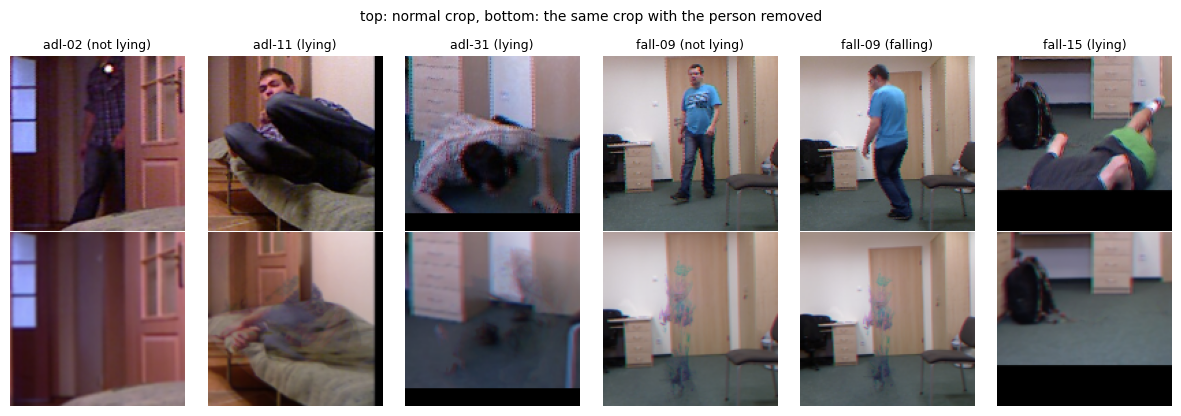

macro F1 of always answering 'not lying': {'all': 0.26, 'ADL videos': 0.281, 'fall videos': 0.19}


,network,macro F1 normal,macro F1 person removed,ADL videos: normal,ADL videos: removed,fall videos: normal,fall videos: removed
0,small CNN,0.592,0.439,0.543,0.361,0.650,0.509
1,MobileNetV2,0.677,0.507,0.575,0.497,0.806,0.462
2,ResNet18,0.622,0.482,0.508,0.424,0.804,0.518
3,ResNet50,0.665,0.465,0.555,0.425,0.824,0.489


In [11]:
EMPTY = PROC / "crops128_empty.npz"
if not EMPTY.exists():
    out = []
    for video, d in boxes.groupby("video", sort=False):
        files = frames_of(video)
        images = [cv2.GaussianBlur(cv2.imread(str(files[k])), (5, 5), 0) for k in sorted(files)[::5]]
        background = cv2.cvtColor(np.median(images, axis=0).astype(np.uint8), cv2.COLOR_BGR2RGB)
        out += [crop_person(background, (r.x, r.y, r.w, r.h)) for r in d.itertuples()]
    np.savez(EMPTY, crops=np.stack(out))
empty = np.load(EMPTY)["crops"][keep]
X_empty = torch.from_numpy(empty).permute(0, 3, 1, 2).to(device)

fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for col, (v, k) in enumerate([("adl-02", 0), ("adl-11", 2), ("adl-31", 2), ("fall-09", 0), ("fall-09", 1), ("fall-15", 2)]):
    j = int(np.flatnonzero((frames.video == v).to_numpy() & (y == k))[5])
    axes[0, col].imshow(crops[j]); axes[0, col].set_title(f"{v} ({NAMES[k]})", fontsize=9); axes[1, col].imshow(empty[j])
for ax in axes.flat: ax.axis("off")
plt.suptitle("top: normal crop, bottom: the same crop with the person removed", fontsize=10); plt.tight_layout(); plt.show()

rows = []
for name in MODELS:
    normal, removed = np.zeros(len(y), int), np.zeros(len(y), int)
    for test in range(1, 6):
        net = make(name).to(device)
        net.load_state_dict(torch.load(CNN / f"strict_{name}_test{test}.pt".replace(" ", ""), map_location=device, weights_only=True))
        index = torch.from_numpy(np.flatnonzero(GROUPS["strict"] == test)).to(device)
        normal[index.cpu()], removed[index.cpu()] = predict(net, index), predict(net, index, X_empty)
    rows.append({"network": name, "macro F1 normal": f1_score(y, normal, average="macro"), "macro F1 person removed": f1_score(y, removed, average="macro"),
                 "ADL videos: normal": f1_score(y[~fall_frame], normal[~fall_frame], average="macro"), "ADL videos: removed": f1_score(y[~fall_frame], removed[~fall_frame], average="macro"),
                 "fall videos: normal": f1_score(y[fall_frame], normal[fall_frame], average="macro"), "fall videos: removed": f1_score(y[fall_frame], removed[fall_frame], average="macro")})
print("macro F1 of always answering 'not lying':", {n: round(f1_score(y[m], np.zeros(m.sum(), int), average="macro"), 3)
      for n, m in [("all", np.ones(len(y), bool)), ("ADL videos", ~fall_frame), ("fall videos", fall_frame)]})
removed_table = pd.DataFrame(rows).round(3)
removed_table

💡 **Interpretation:** without the person the score falls (0.62-0.68 → **0.46-0.51** for the pretrained ones) but stays well above always *not lying* (0.26): part of the answer does **not** come from the visible person.
It can be the room, the place of the crop, or a still person left in the background (see `adl-11`): this test cannot separate them.

## Step 10 — Where does the CNN look? (Grad-CAM)

**Grad-CAM** colours the parts of the image that push the network towards its answer (red = important). We use ResNet18 on **test** images (networks that never saw these videos).

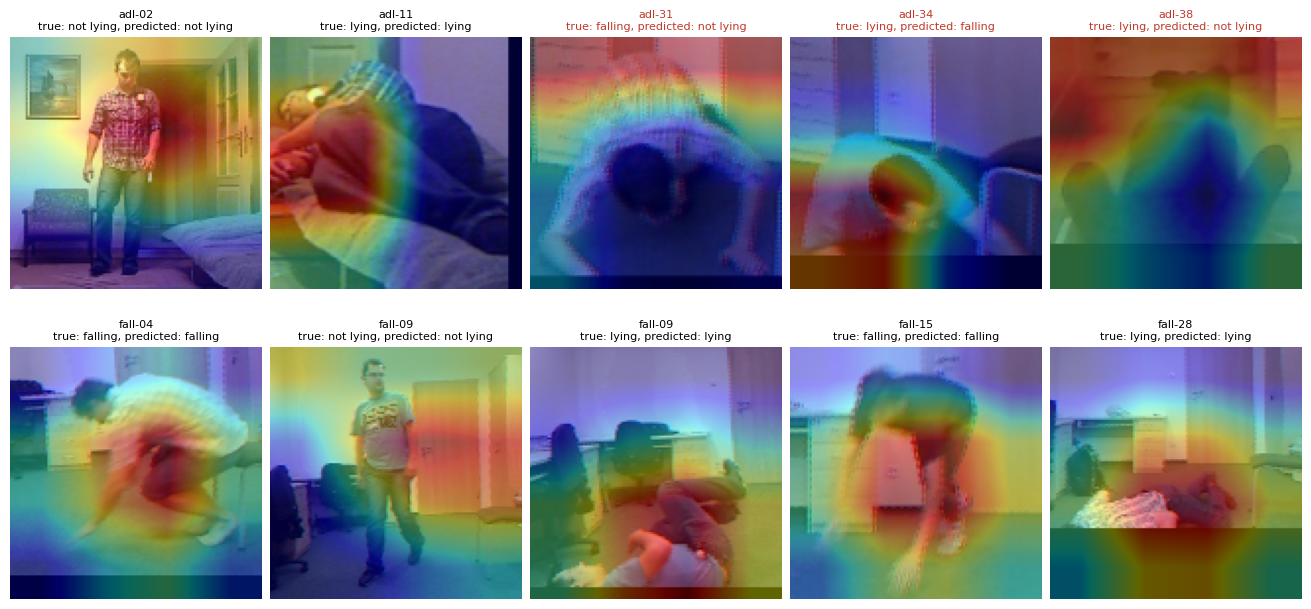

In [12]:
def gradcam(net, image):
    keep_it = {}
    def hook(module, inputs, output):
        output.retain_grad(); keep_it["o"] = output
    handle = net.layer4.register_forward_hook(hook)
    net.eval(); net.zero_grad()
    score = net((image[None].float() / 255 - MEAN) / STD)
    answer = int(score.argmax())
    score[0, answer].backward(); handle.remove()
    o = keep_it["o"]
    heat = torch.relu((o.grad.mean((2, 3), keepdim=True) * o).sum(1))[0].detach().cpu().numpy()
    return answer, cv2.resize(heat / (heat.max() + 1e-8), (128, 128))

picks = [("adl-02", 0), ("adl-11", 2), ("adl-31", 1), ("adl-34", 2), ("adl-38", 2), ("fall-04", 1), ("fall-09", 0), ("fall-09", 2), ("fall-15", 1), ("fall-28", 2)]
fig, axes = plt.subplots(2, 5, figsize=(13, 6.2), layout="constrained")
for ax, (v, k) in zip(axes.flat, picks):
    index = np.flatnonzero((frames.video == v).to_numpy() & (y == k)); j = int(index[len(index) // 2])
    net = make("ResNet18").to(device)
    net.load_state_dict(torch.load(CNN / f"strict_ResNet18_test{strict_of[v]}.pt", map_location=device, weights_only=True))
    answer, heat = gradcam(net, X[j])
    ax.imshow(crops[j]); ax.imshow(heat, cmap="jet", alpha=0.4); ax.axis("off")
    ax.set_title(f"{v}\ntrue: {NAMES[k]}, predicted: {NAMES[answer]}", fontsize=8, color="black" if answer == k else "#c0392b")
plt.show()

💡 **Interpretation:** in these 10 examples (7 right) the red zone is on the body or the floor around it for the *falling* and *lying* images of falls, but beside the person in `adl-02` and `fall-09` (*not lying*) and on the wall in two of the three errors (`adl-31`, `adl-38`).
The network does use what is around the person, but 10 images are only examples, not a proof.

## Step 11 — Save for the final benchmark (notebook 13)

In [13]:
final = frame_scores[frame_scores.method.isin(MODELS)].merge(video_table.rename(columns={"network": "method"}), on="method").merge(
    sizes.rename(columns={"network": "method"}), on="method").merge(removed_table.rename(columns={"network": "method"})[["method", "macro F1 person removed"]], on="method")
final.to_csv(PROC / "results_cnn.csv", index=False)
out = frames.copy()
for (groups, name, seed), (p, _) in results.items():
    out[f"{groups} {name} {seed}"] = p - 1          # back to the labels of the dataset: -1, 0, 1
out.to_csv(PROC / "predictions_cnn.csv", index=False)
print(final.shape, out.shape)

(4, 15) (11027, 19)


💡 **Interpretation:** one line per network, and the 16 predictions of each frame (4 networks × 3 strict + 1 random), ready for notebook 13.

## What we learned

1. **Pretrained CNNs recognise postures better than HOG and colour when all learn from the same 3 groups** (strict macro F1 0.628 to 0.689, against 0.581 and 0.594). Two of them, MobileNetV2 and ResNet50, also pass the best of part A (0.662), which learnt from 4 groups.
   The gain is small, and no CNN beats the accuracy of colour + SVM (0.784). The comparison is not perfect: CNNs see bigger crops, learn with class weights, and use ImageNet.
2. **The network chosen on validation is ResNet50** (0.725, test 0.671). MobileNetV2 is better on the test (0.689) with 10 times fewer parameters, but choosing it for its test score would not be fair. The final choice is in notebook 13.
3. **Overfitting is strong:** 0.99 in training, 0.66-0.68 in validation. A CNN from scratch does not work here (0.495 on average, from 0.42 to 0.59).
4. **Random groups hide this:** 0.84-0.86 for the three pretrained networks, but 0.63-0.69 with strict groups.
5. **ADL rooms remain the hard part:** *falling* is recognised in 0.34-0.46 of its frames in ADLs, and in 0.76-0.79 in fall videos, where the office is always known.
6. **The networks also use something else than the visible person:** with the person removed they still get 0.46-0.51. We cannot say exactly what (room, place of the crop, or leftovers of the person).
7. **The video decision is still too weak:** 49/70 (MobileNetV2, ResNet50). A posture alone is not a fall: the **movement** is missing.

**Limits:** 5 groups only, and all the falls are in one office. Every group is the test once and the validation once, so the validation is not completely separate from the test. The number of epochs and the learning rates were fixed after a short trial on one split (test group 1), and 8 epochs may be a little short for ResNet50 (its validation curve is still rising).

**Next notebook (12):** **skeletons over time** (LSTM and GNN), which do not see the room and can use the **movement**.